<a href="https://colab.research.google.com/github/MasaruGuzman/MA1031.317FJ/blob/main/Situacion_Problema_Etapa_1_Analisis_Estadistico.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Situación Problema Etapa 1
Juan Masaru Guzman Azano - A01643073

Eduardo Li Pan - A01642907

Luis Daniel Cárdenas Peredo - A01648780

MA1031.317 - Análisis estadístico (Gpo 317)

Grupo 317

Brenda Ivette Gatcía Maya

3 de junio de 2026

## Instrucciones

Resolver la siguiente actividad:

### Actividad de Correlación y Regresión

### Situación Problema (Etapa 1)

Una agencia de autos seminuevos quiere predecir el precio de venta de un automóvil de marca Camaro. Se recolectaron 31 datos de los precios de venta de los autos tomando en cuenta variables como antigüedad, kilometraje (miles), condición (mala, promedio o excelente) y si el auto ha tenido un sólo dueño.

Base de datos:  Basededatos_SituacionProblemaE1 (1).xlsx Descargar Basededatos_SituacionProblemaE1 (1).xlsx

-  Construya un diagrama de dispersión para la antigüedad y el precio. ¿Qué tipo de modelo de regresión utilizaría?  ¿Considera adecuado usar un modelo lineal?
- Construya un diagrama de dispersión para el kilometraje y el precio. ¿Qué tipo de modelo utilizaría?  ¿Considera adecuado usar un modelo lineal?
- Ajuste un modelo de regresión lineal múltiple para estimar el precio de venta con base en la antigüedad y el kilometraje. ¿Considera el modelo apto para los datos? justifique su respuesta.
- Ajuste un modelo de regresión lineal múltiple considerando todas las variables proporcionadas. ¿Considera que este modelo es adecuado para  estimar el precio de venta? ¿Por qué?
- Lea la rúbrica para saber qué criterios serán evaluados en la entrega de la actividad.


### Planteamiento del problema
- Define claramente la variable respuesta y las variables regresoras, justificando su elección. Especifique la interpretación de cada variable. En el caso de las variables categóricas diga cuántas categorías tiene cada una y cómo transformarlas a numéricas.


### Análisis exploratorio de datos
- Presenta estadísticas descriptivas y gráficos adecuados; identifica patrones y posibles anomalías. Presenta cada uno de los diagramas de dispersión solicitados. Los diagramas tienen título, así como títulos en los ejes. Interpreta los resultados obtenidos.


### Interpretación de la matriz de correlación
- Analiza correctamente todas las correlaciones e identifica posibles problemas de multicolinealidad.

### Estimación del modelo
- Ajusta correctamente el modelo y reporta la ecuación estimada completa. Describe qué representa cada una de las variables del modelo.


### Bondad de ajuste
- Muestra el coeficiente R^2 e interpreta correctamente los resultados obtenidos


### Gráficos
- Elabora varios gráficos que justifican los resultados obtenidos. Los gráficos tienen títulos, así como títulos en los ejes.


### Elaboración del reporte
- Presenta un reporte con portada, planteamiento del problema, gráficos y conclusiones. El reporte es claro sin errores de ortografía, redacción y/o gramática.

In [ ]:
# librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import seaborn as sns

In [ ]:
# Mi drive no me aparecía sin esto

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Cargar y preparar la base de datos




In [ ]:
datos = pd.read_excel("/content/drive/MyDrive/MA1031.317FJ/Situación Problema/Basededatos_SituacionProblemaE1 (1).xlsx")
datos.head()

,Precio de Venta,Antigüedad,Kilometraje,Condición,Unnamed: 4,Unnamed: 5
0,(pesos),(en años),(miles),Promedio,Excelente,Único Dueño
1,60000,9,112,1,0,1
2,54000,9,159,0,0,1
3,59900,8,192,0,0,1
4,110000,7,90,1,0,0


In [ ]:
datos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32 entries, 0 to 31
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Precio de Venta  32 non-null     object
 1   Antigüedad       32 non-null     object
 2   Kilometraje      32 non-null     object
 3   Condición        32 non-null     object
 4   Unnamed: 4       32 non-null     object
 5   Unnamed: 5       32 non-null     object
dtypes: object(6)
memory usage: 1.6+ KB


Como podemos observar, la fila 0 de nuestra base de datos no nos permitiría visualizar la matriz de correlación entre cada columna, por lo que lo siguiente es retirar esa fila para después mostrar la matriz de correlación. Además se va a cambiar el dato de la fila 0 a estado y si tiene único dueño.

Además, todas las columnas estan fijadas como objetos, por lo que es necesario pasarlas a valores numericos.



In [ ]:
# Primero cambiamos los nombres de las columnas
nuevos_columnas = [
    "Precio",
    "Antiguedad",
    "Kilometraje",
    "Condicion",
    "Excelente",
    "Unico_Dueno"
]
datos.columns = nuevos_columnas
# Ahora usamos drop() para eliminar la fila 0
datos = datos.drop(index=0)

# ahora cambiamos los datos de objetos a su respectivo tipo numérico
datos['Precio']=datos['Precio'].astype(float)
datos['Antiguedad']=datos['Antiguedad'].astype(int)
datos['Kilometraje']=datos['Kilometraje'].astype(int)
datos['Condicion']=datos['Condicion'].astype(int)
datos['Excelente']=datos['Excelente'].astype(int)
datos['Unico_Dueno']=datos['Unico_Dueno'].astype(int)
datos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31 entries, 1 to 31
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Precio       31 non-null     float64
 1   Antiguedad   31 non-null     int64  
 2   Kilometraje  31 non-null     int64  
 3   Condicion    31 non-null     int64  
 4   Excelente    31 non-null     int64  
 5   Unico_Dueno  31 non-null     int64  
dtypes: float64(1), int64(5)
memory usage: 1.6 KB


Como podemos observar, ahora todas las variables son de tipo numérico.

## 1. Análisis de distribución entre antigüedad y precio

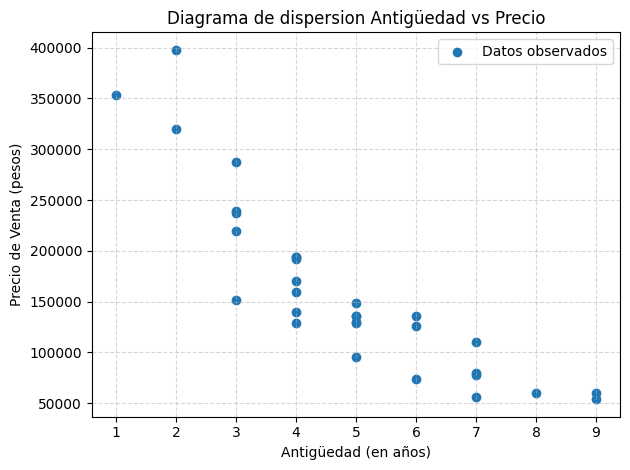

In [ ]:
plt.scatter(datos['Antiguedad'], datos['Precio'], label = "Datos observados")
plt.xlabel("Antigüedad (en años)")
plt.ylabel("Precio de Venta (pesos)")
plt.title("Diagrama de dispersion Antigüedad vs Precio")
plt.grid(True,  linestyle='--', alpha=0.5)
plt.legend( loc="upper right")
plt.tight_layout()
plt.show()

En este diagrama de dispersión se considera como variable dependiente (y) a Precio de Venta y como variable independiente (x) a Antigüedad.

Como se puede observar, la relación entre la antigüedad y el precio de un vehículo no parece ser lineal. Pues a medida que aumenta la antigüedad, el precio disminuye a una tasa no constante. Esto indica que el modelo presenta una curvatura en la relación entre ambas variables. A simple vista esta distribución muestra una gran similitud a la de una relación inversa. Sin embargo, otros modelos como el cuadrático y el exponencial pueden analizarse para determinar cuál presenta un mejor ajuste a los datos.

- Por un lado, el modelo cuadrático podría ser empleado, pues los datos muestran un comportamiento similar al de la sección de una parábola decreciente.

- Por otro lado, podría emplearse el modelo exponencial, puesto que el precio disminuye rápidamente en valores bajos de antigüedad, para posteriormente volverse más gradual. similar a una curva de decaimiento exponencial, donde se aproxima un valor límite sin alcanzarlo.

## 2. Análisis de distribución entre kilometraje y precio

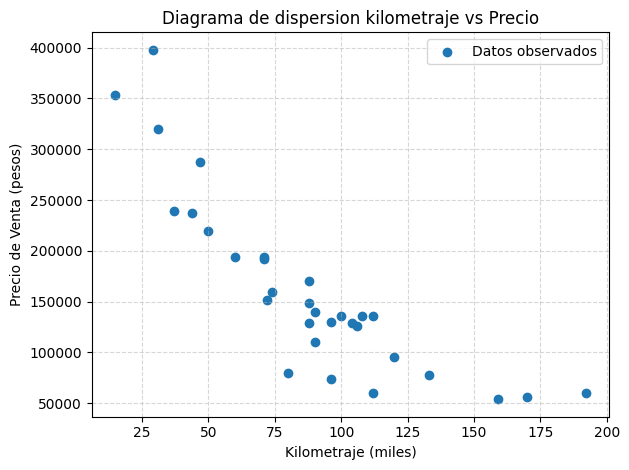

In [ ]:
plt.scatter(datos['Kilometraje'], datos['Precio'], label = "Datos observados")
plt.xlabel("Kilometraje (miles)")
plt.ylabel("Precio de Venta (pesos)")
plt.title("Diagrama de dispersion kilometraje vs Precio")
plt.grid(True,  linestyle='--', alpha=0.5)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

En este diagrama de dispersión se considera como variable dependiente (y) a Precio de Venta y como variable independiente (x) a Kilometraje.

Como puede observarse, existe una relación negativa entre ambas variables, ya que a medida que aumenta el kilometraje, se reduce el precio de venta.

Al igual que en el diagrama de dispersión pasado, podemos observar que la tasa de cambio no parece ser constante. Además de que cuenta con una trayectoria similar, por lo que podemos plantear una conclusión similar. A simple vista parece ser una regresión inversa, aunque vale la pena analizarla con una regresión cuadrática y una exponencial para determinar cual cuenta con mayor ajuste a los datos presentados.

## Análisis de correlación



In [ ]:
# Guardamos la matriz de correlación como variable para después emplearla en una representación visual
corr_matrix = datos.corr()
corr_matrix

,Precio,Antiguedad,Kilometraje,Condicion,Excelente,Unico_Dueno
Precio,1.000000,-0.872438,-0.856593,-0.076708,0.713299,-0.658768
Antiguedad,-0.872438,1.000000,0.844503,0.124575,-0.504309,0.461581
Kilometraje,-0.856593,0.844503,1.000000,-0.030993,-0.538164,0.598070
Condicion,-0.076708,0.124575,-0.030993,1.000000,-0.345425,-0.176540
Excelente,0.713299,-0.504309,-0.538164,-0.345425,1.000000,-0.635489
Unico_Dueno,-0.658768,0.461581,0.598070,-0.176540,-0.635489,1.000000


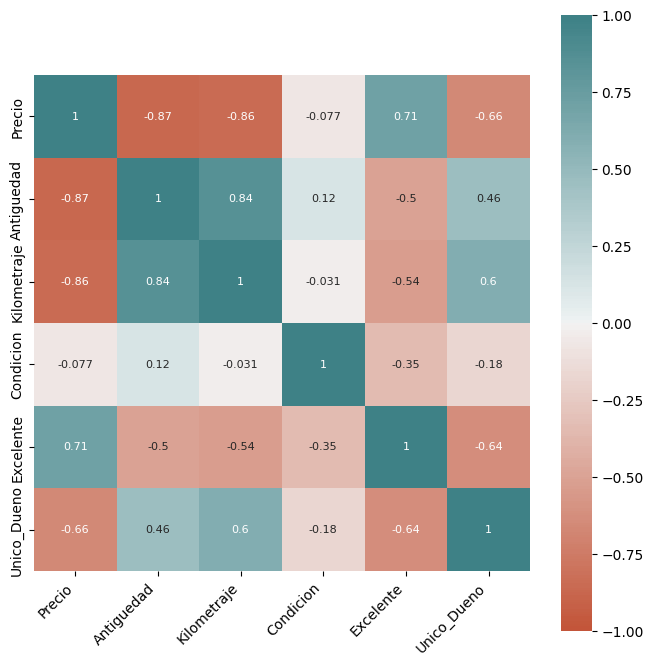

In [ ]:
# Heatmap for correlation matrix
# ==============================================================================
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(8, 8))

sns.heatmap(
    corr_matrix,
    annot     = True,
    cbar      = True,
    annot_kws = {"size": 8},
    vmin      = -1,
    vmax      = 1,
    center    = 0,
    cmap      = sns.diverging_palette(20, 200, n=200),
    square    = True,
    ax        = ax
)

ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation = 45,
    horizontalalignment = 'right',
)

ax.tick_params(labelsize = 10)

Como sabemos, se quiere predecir la variable del precio de venta en base al resto de variables. Y como se puede observar, todas las variables, exceptuando Excelente, tienen una correlación inversa. La correlación de cada variable de orden mayor a menor es:
1. Antigüedad
2. Kilometraje
3. Excelente
4. Único Dueño
5. Condición

En este caso, por requisitos de la actividad vamos a predecir como variable dependiente a precio de venta, en base a las variables independientes de antigüedad y kilometraje, que son las variables con mayor correlación de acuerdo a la matriz.

## 3. Regresión Lineal Múltiple - estimar precio en base a antigüedad y kilometraje

### Creación del modelo

In [ ]:
modelo = smf.ols(formula='Precio~Antiguedad+Kilometraje', data=datos)
modelo = modelo.fit()
print(modelo.summary())

                            OLS Regression Results                            
Dep. Variable:                 Precio   R-squared:                       0.811
Model:                            OLS   Adj. R-squared:                  0.798
Method:                 Least Squares   F-statistic:                     60.15
Date:                Mon, 08 Jun 2026   Prob (F-statistic):           7.31e-11
Time:                        17:24:45   Log-Likelihood:                -370.44
No. Observations:                  31   AIC:                             746.9
Df Residuals:                      28   BIC:                             751.2
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept    3.504e+05   1.89e+04     18.590      

Recordemos que la hipótesis nula `H0` para una regresión lineal indica que si el p-valor es mayor a 0.05, el coeficiente calculado no afecta al modelo, puesnuestro : $\beta = 0$. Sabiendo esto, debemos analizar el p-valor de cada $\beta$ calculado para poder definir si es necesario eliminar alguna de las variables.
- Intercept: p-valor = 0.000 < 0.05, por lo que se anula `H0`.
- Antiguedad: p-valor = 0.002 < 0.05, por lo que se anula `H0`.
- Kilometraje: p-valor = 0.011 < 0.05, por lo que se anula `H0`.

Ahora que sabemos que para los 3 coeficientes el p-valor anula `H0`, no es necesario eliminar variables, por lo que ya podemos construir nuestra ecuación de regresión en base a la formula general, la cuál es la siguiente:

$$\hat{y}=\beta_0+\beta_1 x_1+\beta_2 x_2$$

Por lo que nuestra ecuación de regresión final se vería de la siguiente manera:

$$\hat{y}=3.504\times10^5-2.274\times10^4 x_1-899.6808x_2$$

Donde `x1` es antigüedad y `x2` es kilometraje.

Otro valor en el que hay que fijarse al momento de determinar si un modelo de regresión es válido o no es el coeficiente `R^2`, este coeficiente cuenta con un valor entre 0 y 1, el cual indica el porcentaje de de la variabilidad de la variable dependiente que es explicada por el modelo. Para modelos de regresión lineal múltiple, se recomienda usar el valor ajustado de `R^2`, pues toma en cuenta una penalización por cada variable que no aporte a predecir el modelo. En nuestro caso, `R^2 = 0.798`, lo que indica que el modelo logra explicar un 79.8% de la variabilidad de los precios de venta en función de la antigüedad y el kilometraje.


### Cálculo de predicciones del modelo

In [ ]:
## Construimos la ecuación de regresión para calculos en el modelo
y_aprox = (3.504e5) - (2.274e4 * datos['Antiguedad']) - (899.6808 * datos['Kilometraje'])
y_aprox

,0
1,44975.7504
2,2690.7528
3,-4258.7136
4,110248.7280
5,119245.5360
6,71562.4536
7,38274.2640
8,113195.7504
9,118593.8352
10,127590.6432


Estos valores corresponden a las predicciones para cada observación del modelo, en otras palabras, las 31 estimaciones del precio del vehículo en base a la antigüedad y kilometraje de este.

### Calculo de errores

In [ ]:
errores = datos['Precio'] - y_aprox
errores

,0
1,15024.2496
2,51309.2472
3,64158.7136
4,-248.7280
5,-39485.5360
6,6437.5464
7,17725.7360
8,22804.2496
9,7306.1648
10,-53590.6432


In [ ]:
error_porcentual = (errores.abs().sum() / datos['Precio'].sum()) * 100
print(f"El error porcentual total es: {error_porcentual:.2f}%")

El error porcentual total es: 17.32%


Estos calculos nos servirán para el análisis gráfico.

### Gráficos

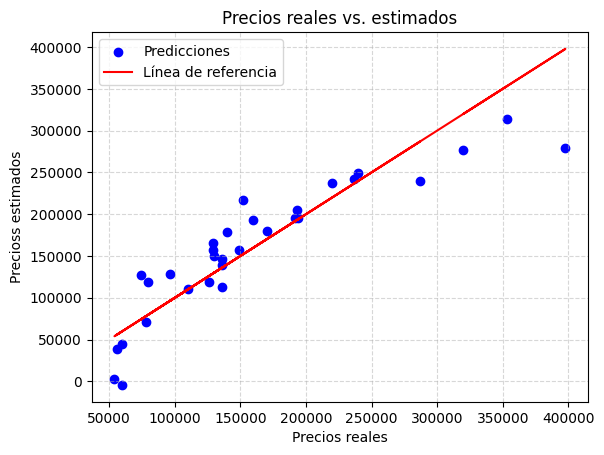

In [ ]:
plt.scatter(datos['Precio'], y_aprox, color = 'blue', label='Predicciones')
plt.plot(datos['Precio'], datos['Precio'], color = 'red', label='Línea de referencia')
plt.xlabel('Precios reales')
plt.ylabel('Precioss estimados')
plt.title('Precios reales vs. estimados')
plt.grid(True,  linestyle='--', alpha=0.5)
plt.legend(loc='upper left')
plt.show()

En este gráfico mostramos los precios reales vs los estimados. Para evaluar la exactitud de las predicciones, se tiene que considerar que a menor distancia de cada punto azul respecto a la línea roja, mayor es la fidelidad de las estimaciones hechas por el modelo.

De este gráfico podemos interpretar que la mayoría de las observaciones se encuentran cercanas a la línea de referencia, sin embargo, se presenta una mayor dispersión cerca de los límites inferiores y superiores, pues en los vehículos con precios bajos y precios elevados el modelo tiende a subestimar algunos valores.

### Análisis gráfico de los errores

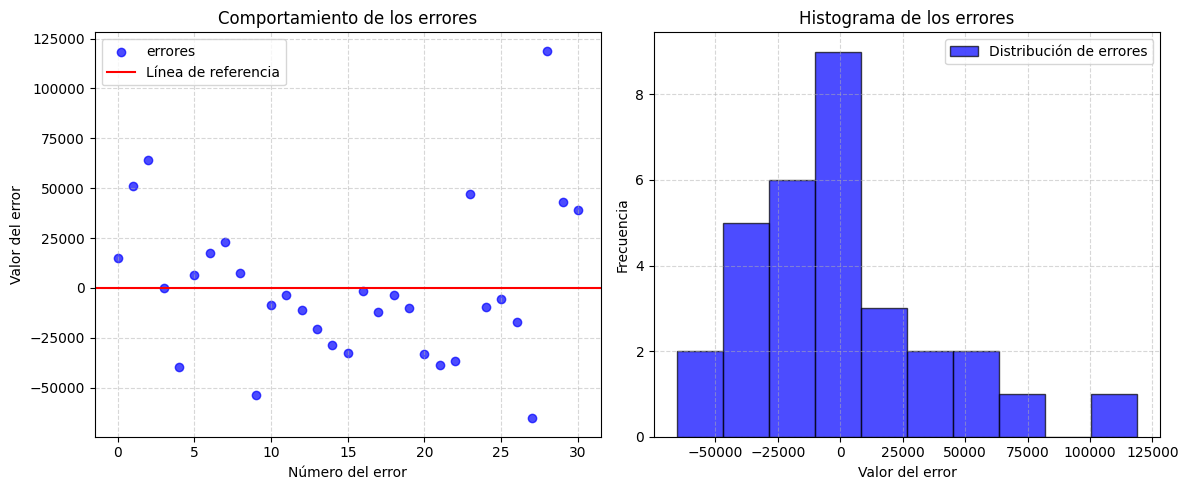

In [ ]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))

# Gráfico de dispersión de errores
axes[0].scatter(range(len(errores)), errores, color='blue', alpha=0.7, label = "errores")
axes[0].axhline(y=0, color='red', linestyle='-', linewidth=1.5, label = "Línea de referencia")
axes[0].set_xlabel('Número del error')
axes[0].set_ylabel('Valor del error')
axes[0].set_title('Comportamiento de los errores')
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend(loc = "upper left")

# Histograma de errores
axes[1].hist(errores, color='blue', edgecolor='black', alpha=0.7, label = "Distribución de errores")
axes[1].set_xlabel('Valor del error')
axes[1].set_ylabel('Frecuencia')
axes[1].set_title('Histograma de los errores')
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend(loc = "upper right")
plt.tight_layout()
plt.show()

En esta sección se presentan 2 gráficos que analizan el comportamiento de los residuos (errores) del modelo, el primero (izquierda), muestra la dispersión y el comportamiento de los errores. Por otro lado, el segundo (derecha) es un histograma que muestra la frecuencia de los errores y su distribución.

### 1. Comportamiento de los errores
- Como se puede apreciar aquí, la mayoría de los residuos se distribuyen de forma aleatoria y cercana a la línea ($y=0$), lo que indica que se satisface la homocedasticidad (de la optativa de ciencia de datos). Sin embargo, en los extremos de la muestra se evidencia una mayor dispersión, confirmando lo que veíamos en el gráfico de precios reales vs estimados.

### 2. Histograma de los errores
- En este gráfico se puede observar cómo los errores cuentan con una asimetría hacia la derecha (sesgo positivo). Además podemos apreciar como la mayoría de frecuencia de los errores está concentrada en 0 (lo que valida que el modelo no está sesgado de forma generalizada). La forma alargada de la derecha muestra el impacto de los pocos vehículos subestimados por el modelo.

## 4. Regresión Lineal Múltiple - estimar precio en base a todas las variables

Dado que ya se cuenta con toda la información previa, simplemente saltamos a la creación del modelo.

In [ ]:
# Mostramos cada variable para tenerla a la mano
datos.columns

Index(['Precio', 'Antiguedad', 'Kilometraje', 'Condicion', 'Excelente',
       'Unico_Dueno'],
      dtype='object')

In [ ]:
# "modelof" sera el nombre del modelo final
modelof = smf.ols(formula='Precio~Antiguedad+Kilometraje+Condicion+Excelente+Unico_Dueno', data=datos)
modelof = modelof.fit()
print(modelof.summary())

                            OLS Regression Results                            
Dep. Variable:                 Precio   R-squared:                       0.896
Model:                            OLS   Adj. R-squared:                  0.876
Method:                 Least Squares   F-statistic:                     43.28
Date:                Mon, 08 Jun 2026   Prob (F-statistic):           1.62e-11
Time:                        17:24:46   Log-Likelihood:                -361.13
No. Observations:                  31   AIC:                             734.3
Df Residuals:                      25   BIC:                             742.9
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept    2.973e+05   2.37e+04     12.544      

La tabla nos muestra que el p-valor > 0.05 en varias variables. Es por esto que necesitamos eliminar las variables con p-valor > 0.05; pero para hacerlo, tenemos que ir eliminando una por una el p-valor más grande, pues este puede ir disminuyendo para el resto de variables conforme vamos eliminándolas. En este caso, empezamos eliminando Unico_Dueno.

In [ ]:
# "modelof" sera el nombre del modelo final
modelof = smf.ols(formula='Precio~Antiguedad+Kilometraje+Condicion+Excelente', data=datos)
modelof = modelof.fit()
print(modelof.summary())

                            OLS Regression Results                            
Dep. Variable:                 Precio   R-squared:                       0.893
Model:                            OLS   Adj. R-squared:                  0.877
Method:                 Least Squares   F-statistic:                     54.50
Date:                Mon, 08 Jun 2026   Prob (F-statistic):           2.88e-12
Time:                        17:24:46   Log-Likelihood:                -361.57
No. Observations:                  31   AIC:                             733.1
Df Residuals:                      26   BIC:                             740.3
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept    2.875e+05   2.06e+04     13.933      

Como se puede observar, aún hay variables con un p-valor > 0.05, pero comparado a antes de eliminar Unico_Dueno, ahora son menores. La siguiente variable a eliminar es Condicion.

In [ ]:
# "modelof" sera el nombre del modelo final
modelof = smf.ols(formula='Precio~Antiguedad+Kilometraje+Excelente', data=datos)
modelof = modelof.fit()
print(modelof.summary())

                            OLS Regression Results                            
Dep. Variable:                 Precio   R-squared:                       0.884
Model:                            OLS   Adj. R-squared:                  0.871
Method:                 Least Squares   F-statistic:                     68.76
Date:                Mon, 08 Jun 2026   Prob (F-statistic):           9.16e-13
Time:                        17:24:46   Log-Likelihood:                -362.85
No. Observations:                  31   AIC:                             733.7
Df Residuals:                      27   BIC:                             739.4
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept    2.996e+05   1.94e+04     15.413      

Como podemos apreciar, tras eliminar las variables de Unico_Dueno y Condicion, obtenemos p-valores menores a 0.05 para cada coeficiente, invalidando `H0` para todas las variables; lo que significa que ya se puede trabajar con este modelo. Cabe destacar que la variable kilometraje logro disminuir su p-valor hasta un valor aceptable para invalidar `H0`. Por otro lado, aunque la variable de excelente ya cumplía con la condición, se puede apreciar como esta disminuye de 0.007 hasta 0.000.

Esto nos da que nuestra ecuación de regresión para este modelo es:
$$\hat{y}=2.996\times10^5-2.029\times10^4x_1-627.6644x_2+6.651\times10^4x_3$$


Nuestra R^2 = 0.871, lo que indica que el modelo logra explicar un 87.1% de la variabilidad de los precios de venta en función de la antigüedad y el kilometraje.

### Aproximaciones de y

In [ ]:
y_aproxf = (2.996e5) - (2.029e4 * datos['Antiguedad']) - (627.6644 * datos['Kilometraje']) + (6.651e4 * datos['Excelente'])
y_aproxf

,0
1,46691.5872
2,17191.3604
3,16768.4352
4,101080.2040
5,107356.8480
6,74090.6348
7,50867.0520
8,174071.5872
9,111327.5736
10,117604.2176


### Cálculo de errores

In [ ]:
erroresf = datos['Precio'] - y_aproxf
erroresf

,0
1,13308.4128
2,36808.6396
3,43131.5648
4,8919.7960
5,-27596.8480
6,3909.3652
7,5132.9480
8,-38071.5872
9,14572.4264
10,-43604.2176


In [ ]:
error_porcentualf = (erroresf.abs().sum() / datos['Precio'].sum()) * 100
print(f"El error porcentual total es: {error_porcentualf:.2f}%")

El error porcentual total es: 14.10%


### Gráficos

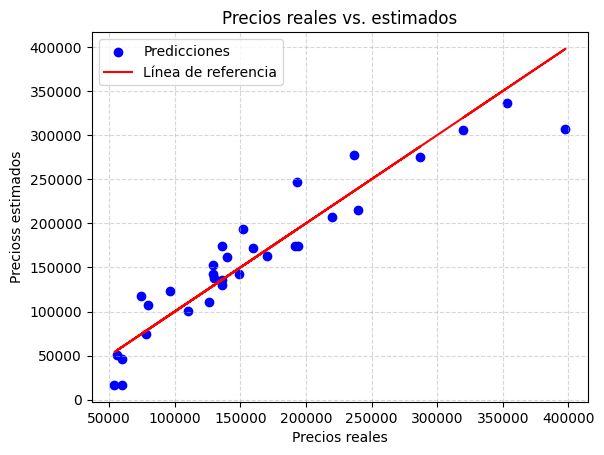

In [ ]:
plt.scatter(datos['Precio'], y_aproxf, color = 'blue', label = "Predicciones")
plt.plot(datos['Precio'], datos['Precio'], color = 'red', label = "Línea de referencia")
plt.xlabel('Precios reales')
plt.ylabel('Precioss estimados')
plt.title('Precios reales vs. estimados')
plt.grid(True,  linestyle='--', alpha=0.5)
plt.legend(loc = "upper left")
plt.show()

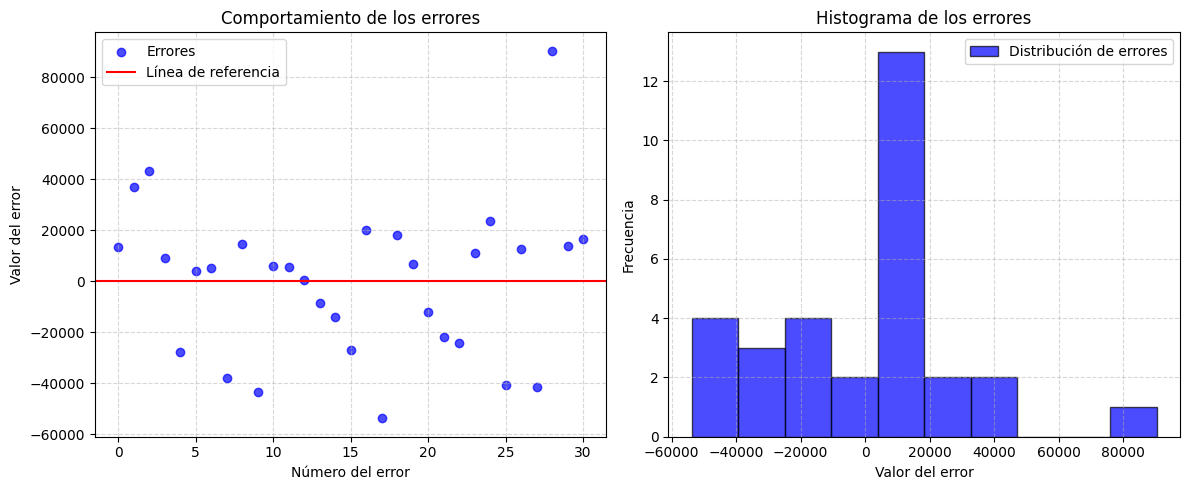

In [ ]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))

# Gráfico de dispersión de errores
axes[0].scatter(range(len(errores)), erroresf, color='blue', alpha=0.7, label = "Errores")
axes[0].axhline(y=0, color='red', linestyle='-', linewidth=1.5, label = "Línea de referencia")
axes[0].set_xlabel('Número del error')
axes[0].set_ylabel('Valor del error')
axes[0].set_title('Comportamiento de los errores')
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend(loc = "upper left")

# Histograma de errores
axes[1].hist(erroresf, color='blue', edgecolor='black', alpha=0.7, label = "Distribución de errores")
axes[1].set_xlabel('Valor del error')
axes[1].set_ylabel('Frecuencia')
axes[1].set_title('Histograma de los errores')
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend(loc = "upper right")

plt.tight_layout()
plt.show()